In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [25]:
dfwh = pd.read_csv(r"C:\Users\DELL\Desktop\python imarticus\Shankhan@7\SOCR-HeightWeight.csv")
dfwh

,Index,Height(Inches),Weight(Pounds)
0,1,65.78331,112.9925
1,2,71.51521,136.4873
2,3,69.39874,153.0269
3,4,68.21660,142.3354
4,5,67.78781,144.2971
...,...,...,...
24995,24996,69.50215,118.0312
24996,24997,64.54826,120.1932
24997,24998,64.69855,118.2655
24998,24999,67.52918,132.2682


In [26]:
dfwh.shape
dfwh.head()


,Index,Height(Inches),Weight(Pounds)
0,1,65.78331,112.9925
1,2,71.51521,136.4873
2,3,69.39874,153.0269
3,4,68.21660,142.3354
4,5,67.78781,144.2971


## feature selection



In [27]:
dfwh.columns
dfwh.drop("Index",axis=1,inplace=True)
dfwh
dfwh.columns = ["Height","Weight"]
dfwh

,Height,Weight
0,65.78331,112.9925
1,71.51521,136.4873
2,69.39874,153.0269
3,68.21660,142.3354
4,67.78781,144.2971
...,...,...
24995,69.50215,118.0312
24996,64.54826,120.1932
24997,64.69855,118.2655
24998,67.52918,132.2682


## NaN

In [28]:
dfwh.isna().sum()
dfwh.isnull().sum()

Height    0
Weight    0
dtype: int64

## error detection

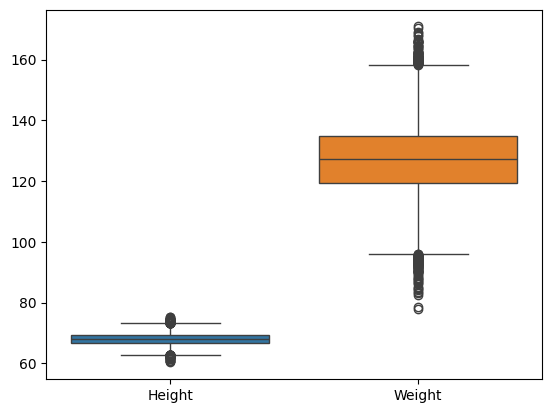

In [29]:
sns.boxplot(dfwh)
plt.show()

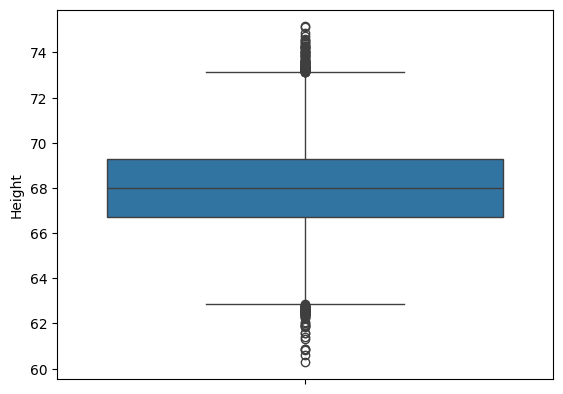

In [30]:
sns.boxplot(dfwh["Height"])
plt.show()

In [31]:
# desc analysis
dfwh["Height"].describe()

count    25000.000000
mean        67.993114
std          1.901679
min         60.278360
25%         66.704397
50%         67.995700
75%         69.272958
max         75.152800
Name: Height, dtype: float64

## IQR


In [32]:
q1 = dfwh["Height"].quantile(0.25)
q1
q3 = dfwh["Height"].quantile(0.75)
q3
iqr = q3-q1
lower = q1-(1.5*iqr)
upper = q3+(1.5*iqr)



## error which are less than lower limit

In [33]:
dfwh["Height"]<lower
dfwh[dfwh["Height"]<lower]

,Height,Weight
412,62.01666,109.08480
1133,62.75039,114.49000
1244,62.64242,100.19820
2186,62.60611,129.76000
2237,62.78196,119.84700
...,...,...
22778,62.48689,111.81650
22945,61.92639,78.01476
23041,62.37478,129.29000
24244,62.26498,104.13480


## error which are less than lower limit

In [34]:
dfwh[dfwh["Height"]>upper]

,Height,Weight
138,73.90107,151.3913
174,73.83364,139.2983
269,73.26872,130.2636
1162,74.24899,150.2167
1383,74.19488,129.0597
...,...,...
23635,73.46216,140.9680
23674,73.55566,149.8402
23896,73.38057,154.3189
24078,73.22107,136.7360


In [35]:
dfwh[(dfwh["Height"]<lower) | (dfwh["Height"]>upper)]
# 88+79

,Height,Weight
138,73.90107,151.3913
174,73.83364,139.2983
269,73.26872,130.2636
412,62.01666,109.0848
1133,62.75039,114.4900
...,...,...
23896,73.38057,154.3189
24078,73.22107,136.7360
24244,62.26498,104.1348
24475,62.68591,118.6002


## data outliers trimming using df copy


In [61]:
df1 = dfwh.copy()
ind = df1[(dfwh["Height"]<lower) | (df1["Height"]>upper)].index
df1.drop(ind,inplace=True)

df1[(dfwh["Height"]<lower) | (df1["Height"]>upper)]

,Height,Weight


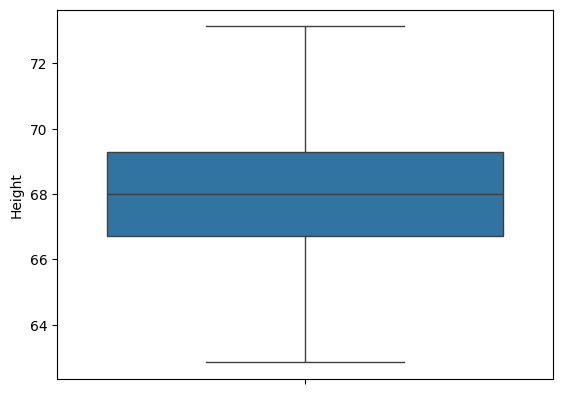

,Height,Weight
0,65.78331,112.9925
1,71.51521,136.4873
2,69.39874,153.0269
3,68.21660,142.3354
4,67.78781,144.2971
...,...,...
24995,69.50215,118.0312
24996,64.54826,120.1932
24997,64.69855,118.2655
24998,67.52918,132.2682


In [62]:
sns.boxplot(df1["Height"])
plt.show()
dfwh
dfwh

## data caping

In [59]:
dfwh[(dfwh["Height"]<lower) | (dfwh["Height"]>upper)]
dfwh["Height"].map(lambda x : lower if x<lower else upper if x>upper else x)

dfwh["Height"]=dfwh["Height"].map(lambda x : lower if x<lower else upper if x>upper else x)
dfwh["Height"]

0        65.78331
1        71.51521
2        69.39874
3        68.21660
4        67.78781
           ...   
24995    69.50215
24996    64.54826
24997    64.69855
24998    67.52918
24999    68.87761
Name: Height, Length: 25000, dtype: float64

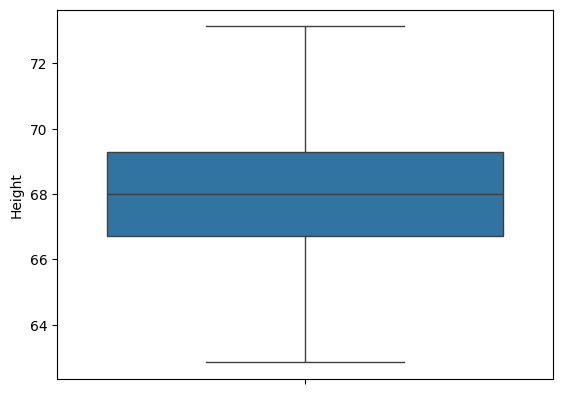

In [60]:
sns.boxplot(dfwh["Height"])
plt.show()